# Suport del contenidor: diferents acers i radis (apartat 3)

**Disseny i assaig de màquines (DiAM)** · J.A. Mayugo, UdG

Factors de seguretat estàtic i a fatiga per als quatre acers i tres radis d'acord, i gràfic de barres.

## Llibreries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['svg.fonttype'] = 'none'

## Dades del problema

In [2]:
m_max, m_min = 1000.0, 250.0   # kg, massa del contenidor ple i buit
d_e, d_i = 100.0, 80.0         # mm, diàmetres exterior i interior de l'eix
D = 120.0                      # mm, diàmetre del reforç central
l1, l2 = 1100.0, 500.0         # mm, distàncies contenidor i cilindre a l'eix de rotació
alpha = np.radians(30)         # angle del pistó respecte la vertical
l_AB, l_CD = 1200.0, 120.0     # mm, longitud de l'eix i del reforç central
g = 9.81                       # m/s2

# Acers: (Sut, Sy, Se'); Se' = None indica que s'estima com 0.5*Sut
acers = {1: (500.0, 370.0, None),
         2: (550.0, 450.0, 305.0),
         3: (600.0, 470.0, None),
         4: (650.0, 500.0, 360.0)}
radis = [3.5, 5.0, 7.5]        # mm

## Funcions

In [3]:
def K_t_rodo_flexio(D_d, r_d):
    """K_t d'un rodó a flexió amb canvi de diàmetre (D_d = D/d, r_d = r/d)."""
    return (0.632 + 0.377*D_d**(-4.4)
            + r_d**(-0.5)*np.sqrt((-0.14 - 0.363*D_d**2 + 0.503*D_d**4)
                                  /(1 - 2.39*D_d**2 + 3.368*D_d**4)))

def K_t_rodo_torsio(D_d, r_d):
    """K_ts d'un rodó a torsió amb canvi de diàmetre (D_d = D/d, r_d = r/d)."""
    return (0.78 + 0.2*D_d**(-10)
            + r_d**(-0.46)*np.sqrt((0.002 - 0.125*D_d**2 + 0.123*D_d**4)
                                   /(1 - 2.75*D_d**2 + 2.55*D_d**4)))

def q_sensibilitat_entalla(r, Sut, cisalla=False):
    """Sensibilitat a l'entalla d'un acer (r en mm, Sut en MPa): q (tracció/flexió) o q_s (tallant)."""
    S = Sut/6.9
    r_in = r/25.4
    if cisalla:
        sqr_a = 0.190 - 2.51e-3*S + 1.35e-5*S**2 - 2.67e-8*S**3
    else:
        sqr_a = 0.246 - 3.08e-3*S + 1.51e-5*S**2 - 2.67e-8*S**3
    return 1/(1 + sqr_a/np.sqrt(r_in))

def tensions_principals(sx, tau):
    """Tensions principals (I >= II >= III) d'un estat pla (sx, 0, tau)."""
    c, rad = sx/2, np.hypot(sx/2, tau)
    A, B = c + rad, c - rad
    if B > 0:
        return A, B, 0.0
    if A > 0:
        return A, 0.0, B
    return 0.0, A, B

def von_mises(s1, s2, s3):
    return np.sqrt(2)/2*np.sqrt((s1 - s2)**2 + (s2 - s3)**2 + (s3 - s1)**2)

def Se_modificat(Sut, Sep, d):
    """Límit de fatiga modificat Se = Sep*ka*kb*kc (mecanitzat, flexió i torsió)."""
    ka = 4.51*Sut**(-0.265)
    if d < 2.79:
        kb = (2.79/7.62)**(-0.107)
    elif d <= 51:
        kb = (d/7.62)**(-0.107)
    else:
        kb = 1.51*d**(-0.157)
    return Sep*ka*kb*1.0

def coeficients_seguretat(Sut, Sy, Sep, r):
    """Coeficients de seguretat estàtic (von Mises) i a fatiga (Goodman modificat amb el criteri de Sines)."""
    R = m_min/m_max
    Fp = m_max*g*l1/(l2*np.cos(alpha))
    M = ((l_AB - l_CD)/2 - r)*Fp/2
    T = l1*m_max/2*g
    I = np.pi*(d_e**4 - d_i**4)/64
    J = np.pi*(d_e**4 - d_i**4)/32
    sig_max, tau_max = M*(d_e/2)/I, T*(d_e/2)/J
    sig_min, tau_min = R*sig_max, R*tau_max
    # estàtic
    SF_e = Sy/von_mises(*tensions_principals(sig_max, tau_max))
    # concentració de tensions (només a les components alternes)
    K_f = 1 + q_sensibilitat_entalla(r, Sut)*(K_t_rodo_flexio(D/d_e, r/d_e) - 1)
    K_fs = 1 + q_sensibilitat_entalla(r, Sut, True)*(K_t_rodo_torsio(D/d_e, r/d_e) - 1)
    # criteri de Sines
    sigma_m = sum(tensions_principals((sig_max + sig_min)/2, (tau_max + tau_min)/2))
    sigma_a = von_mises(*tensions_principals(K_f*(sig_max - sig_min)/2, K_fs*(tau_max - tau_min)/2))
    Se = Se_modificat(Sut, Sep, d_e)
    SF_f = 1/(sigma_m/Sut + sigma_a/Se)
    return SF_e, SF_f

## Càlcul per a tots els acers i radis

In [4]:
SF_e = np.zeros((len(acers), len(radis)))
SF_f = np.zeros((len(acers), len(radis)))
for i, (Sut, Sy, Sep) in enumerate(acers.values()):
    if Sep is None:
        Sep = 0.5*Sut
    for j, r in enumerate(radis):
        SF_e[i, j], SF_f[i, j] = coeficients_seguretat(Sut, Sy, Sep, r)

print("Acer   r [mm]    SF_e    SF_f")
for i, acer in enumerate(acers):
    for j, r in enumerate(radis):
        print(f"{acer if j == 1 else '':>4}   {r:6.2f}   {SF_e[i, j]:6.2f}  {SF_f[i, j]:6.2f}")

Acer   r [mm]    SF_e    SF_f
         3.50     2.63    1.28
   1     5.00     2.63    1.37
         7.50     2.64    1.48
         3.50     3.20    1.49
   2     5.00     3.20    1.59
         7.50     3.21    1.72
         3.50     3.34    1.45
   3     5.00     3.35    1.56
         7.50     3.36    1.69
         3.50     3.55    1.67
   4     5.00     3.56    1.80
         7.50     3.57    1.95


## Representació gràfica

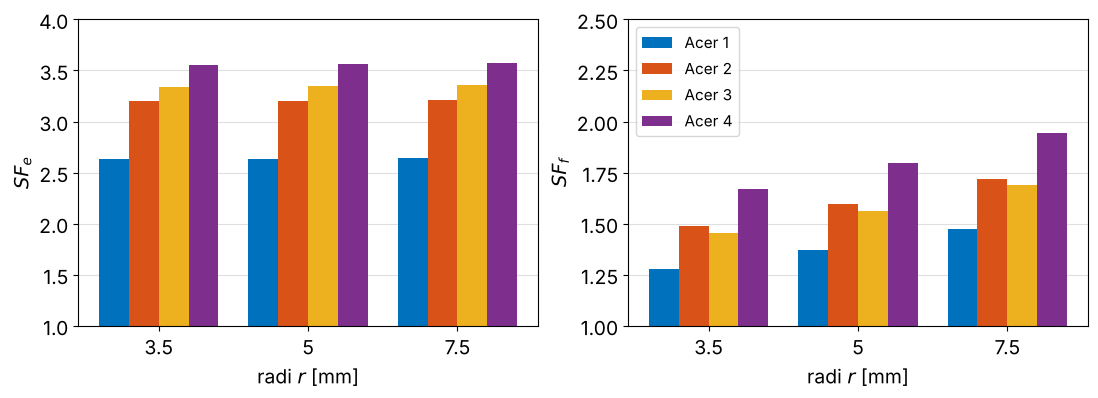

In [5]:
plt.rcParams.update({'font.size': 14})
colors = ['#0072BD', '#D95319', '#EDB120', '#7E2F8E']
x = np.arange(len(radis))
w = 0.2
fig, axs = plt.subplots(1, 2, figsize=(11.2, 4.2))
for ax, SF, etq, lim in ((axs[0], SF_e, '$SF_e$', (1, 4)), (axs[1], SF_f, '$SF_f$', (1, 2.5))):
    for i, acer in enumerate(acers):
        ax.bar(x + (i - 1.5)*w, SF[i], w, color=colors[i], label=f'Acer {acer}')
    ax.set_xticks(x)
    ax.set_xticklabels([f'{r:g}' for r in radis])
    ax.set_xlabel('radi $r$ [mm]')
    ax.set_ylabel(etq)
    ax.set_ylim(*lim)
    ax.grid(True, axis='y', alpha=0.4)
    ax.set_axisbelow(True)
axs[1].legend(loc='upper left', fontsize=11)
fig.tight_layout()
fig.savefig('DiAM_05c_contenidor_Fig2.pdf', bbox_inches='tight')
fig.savefig('DiAM_05c_contenidor_Fig2.svg', bbox_inches='tight')
plt.show()